In [1]:
from google.colab import files
uploaded = files.upload()

Saving winemag-data-130k-v2.csv to winemag-data-130k-v2.csv


In [2]:
import pandas as pd

df = pd.read_csv('/content/winemag-data-130k-v2.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (129971, 14)

First 5 Rows:


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks



Column Names:
['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


In [3]:
# Check duplicate rows
duplicates = df.duplicated().sum()

print("Duplicate Rows Before Removal:", duplicates)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Duplicate Rows After Removal:", df.duplicated().sum())

Duplicate Rows Before Removal: 0
Dataset Shape After Removing Duplicates: (129971, 14)
Duplicate Rows After Removal: 0


In [4]:
# Check duplicate wine reviews using title and description
review_duplicates = df.duplicated(
    subset=['title', 'description']
).sum()

print("Duplicate Reviews:", review_duplicates)

Duplicate Reviews: 9983


In [5]:
# Remove duplicate reviews
df = df.drop_duplicates(
    subset=['title', 'description']
).reset_index(drop=True)

print("Dataset Shape After Deduplication:", df.shape)

print("Remaining Duplicate Reviews:",
      df.duplicated(subset=['title', 'description']).sum())

Dataset Shape After Deduplication: (119988, 14)
Remaining Duplicate Reviews: 0


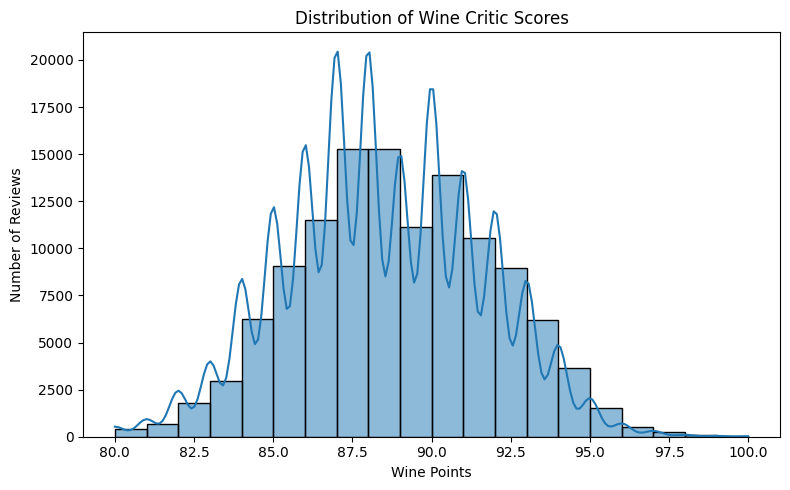

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df['points'], bins=20, kde=True)

plt.title("Distribution of Wine Critic Scores")
plt.xlabel("Wine Points")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.savefig("points_distribution.png", dpi=300)
plt.show()

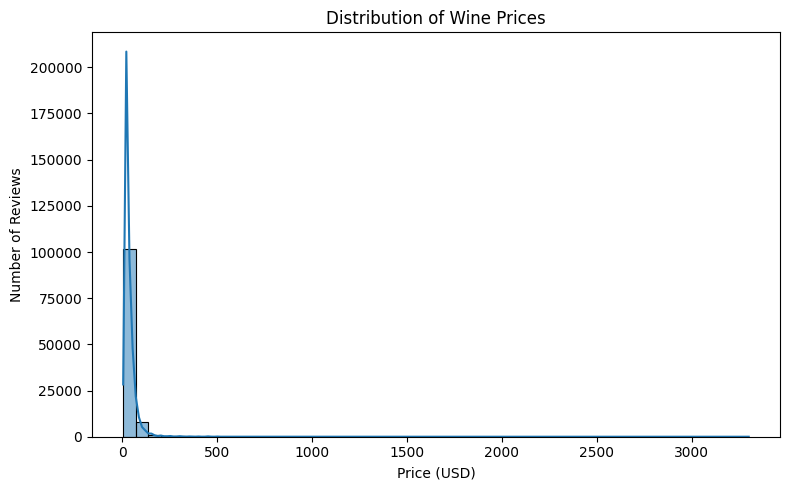

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'].dropna(), bins=50, kde=True)

plt.title("Distribution of Wine Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.savefig("price_distribution.png", dpi=300)
plt.show()

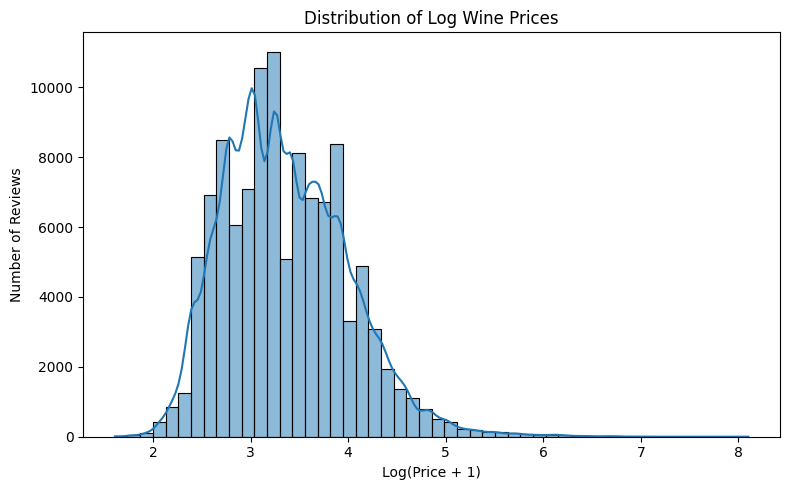

In [8]:
import numpy as np

log_price = np.log1p(df['price'].dropna())

plt.figure(figsize=(8, 5))

sns.histplot(log_price, bins=50, kde=True)

plt.title("Distribution of Log Wine Prices")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.savefig("log_price_distribution.png", dpi=300)
plt.show()

Correlation between Points and Log Price: 0.6169447894525634


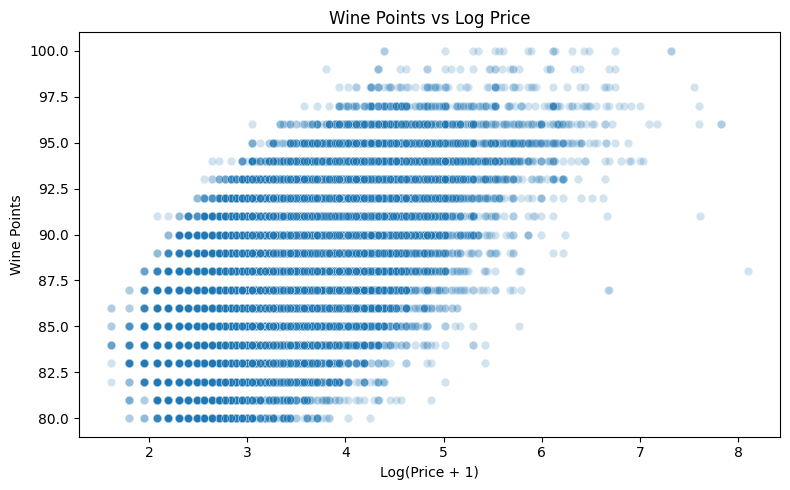

In [9]:
# Calculate correlation
correlation = df['points'].corr(np.log1p(df['price']))

print("Correlation between Points and Log Price:", correlation)

# Create scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x=np.log1p(df['price']),
    y='points',
    alpha=0.2
)

plt.title("Wine Points vs Log Price")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Wine Points")

plt.tight_layout()
plt.savefig("points_vs_log_price.png", dpi=300)
plt.show()

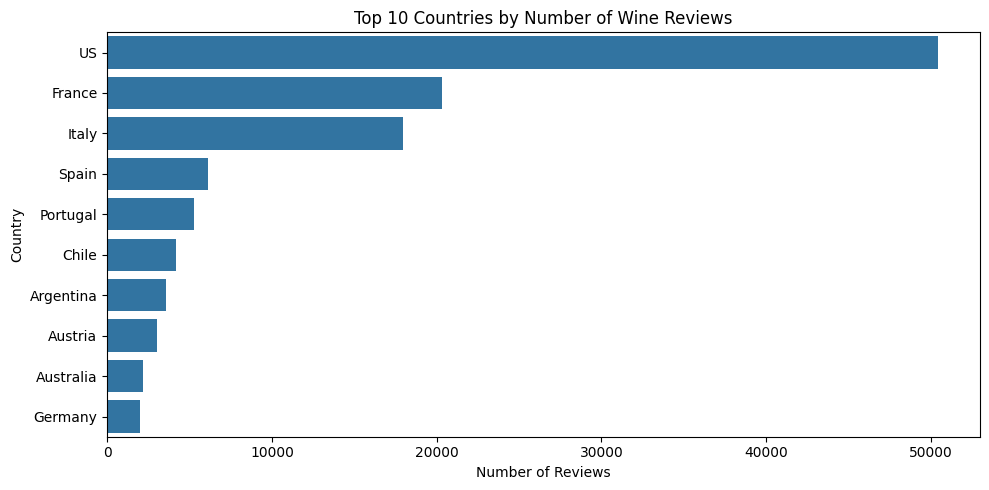

country
US           50457
France       20353
Italy        17940
Spain         6116
Portugal      5256
Chile         4184
Argentina     3544
Austria       3034
Australia     2197
Germany       1992
Name: count, dtype: int64


In [10]:
top_countries = df['country'].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Number of Wine Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig("top_10_countries.png", dpi=300)
plt.show()

print(top_countries)

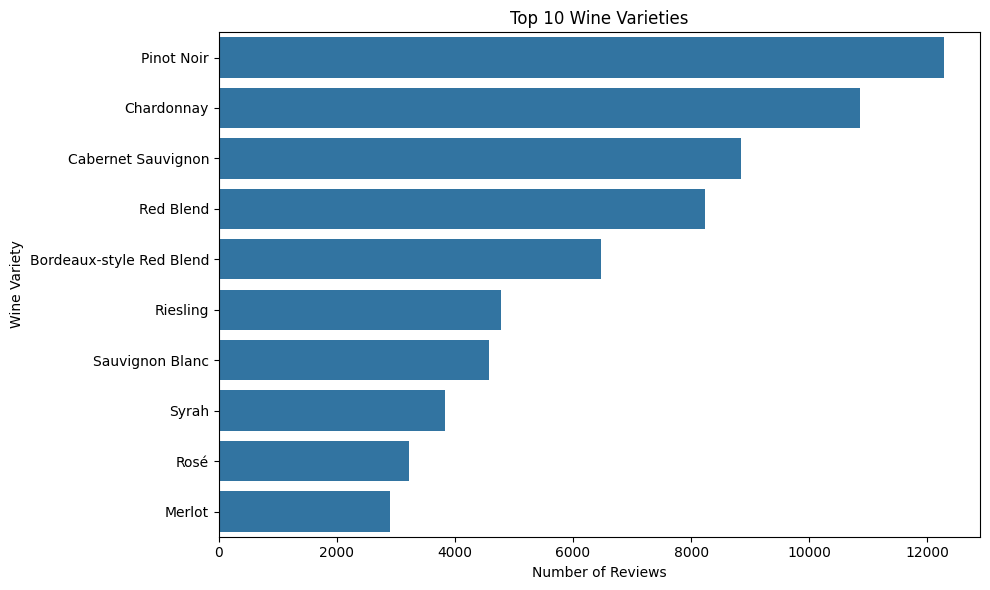

variety
Pinot Noir                  12278
Chardonnay                  10868
Cabernet Sauvignon           8840
Red Blend                    8243
Bordeaux-style Red Blend     6471
Riesling                     4773
Sauvignon Blanc              4575
Syrah                        3828
Rosé                         3220
Merlot                       2896
Name: count, dtype: int64


In [11]:
top_varieties = df['variety'].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_varieties.values,
    y=top_varieties.index
)

plt.title("Top 10 Wine Varieties")
plt.xlabel("Number of Reviews")
plt.ylabel("Wine Variety")

plt.tight_layout()
plt.savefig("top_10_varieties.png", dpi=300)
plt.show()

print(top_varieties)

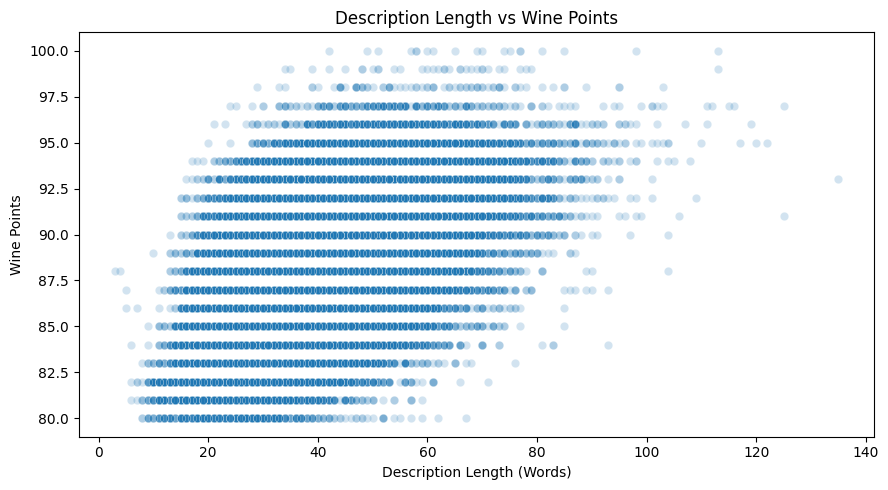

Correlation: 0.5218297932714948


In [12]:
# Calculate description length
df['description_length'] = df['description'].fillna('').apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='description_length',
    y='points',
    alpha=0.2
)

plt.title("Description Length vs Wine Points")
plt.xlabel("Description Length (Words)")
plt.ylabel("Wine Points")

plt.tight_layout()
plt.savefig("description_length_vs_points.png", dpi=300)
plt.show()

print("Correlation:",
      df['description_length'].corr(df['points']))

In [13]:
# Check missing values
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

display(missing_table.sort_values(
    by='Missing Percentage',
    ascending=False
))

,Missing Values,Missing Percentage
region_2,73219,61.021936
designation,34545,28.790379
taster_twitter_handle,29446,24.540787
taster_name,24917,20.766243
region_1,19560,16.301630
price,8395,6.996533
country,59,0.049172
province,59,0.049172
variety,1,0.000833
Unnamed: 0,0,0.000000


In [14]:
import numpy as np

# Create missing price indicator
df['price_missing'] = df['price'].isnull().astype(int)

# Calculate median price
price_median = df['price'].median()

# Fill missing prices with median
df['price_filled'] = df['price'].fillna(price_median)

# Apply log transformation
df['log_price'] = np.log1p(df['price_filled'])

print("Median Price:", price_median)
print("Missing Price Indicators:", df['price_missing'].sum())
print("Remaining Missing Prices:", df['price_filled'].isnull().sum())

display(df[['price', 'price_missing', 'price_filled', 'log_price']].head())

Median Price: 25.0
Missing Price Indicators: 8395
Remaining Missing Prices: 0


,price,price_missing,price_filled,log_price
0,NaN,1,25.0,3.258097
1,15.0,0,15.0,2.772589
2,14.0,0,14.0,2.708050
3,13.0,0,13.0,2.639057
4,65.0,0,65.0,4.189655


In [15]:
# Identify top 10 categories
top_countries = df['country'].value_counts().head(10).index
top_varieties = df['variety'].value_counts().head(10).index

# Group rare categories into Other
df['country_grouped'] = df['country'].fillna('Other').where(
    df['country'].isin(top_countries), 'Other'
)

df['variety_grouped'] = df['variety'].fillna('Other').where(
    df['variety'].isin(top_varieties), 'Other'
)

# Check results
print("Country Categories:")
print(df['country_grouped'].value_counts())

print("\nVariety Categories:")
print(df['variety_grouped'].value_counts())

Country Categories:
country_grouped
US           50457
France       20353
Italy        17940
Spain         6116
Portugal      5256
Other         4915
Chile         4184
Argentina     3544
Austria       3034
Australia     2197
Germany       1992
Name: count, dtype: int64

Variety Categories:
variety_grouped
Other                       53996
Pinot Noir                  12278
Chardonnay                  10868
Cabernet Sauvignon           8840
Red Blend                    8243
Bordeaux-style Red Blend     6471
Riesling                     4773
Sauvignon Blanc              4575
Syrah                        3828
Rosé                         3220
Merlot                       2896
Name: count, dtype: int64


In [16]:
# One-hot encode categorical features
country_encoded = pd.get_dummies(
    df['country_grouped'],
    prefix='country',
    dtype=int
)

variety_encoded = pd.get_dummies(
    df['variety_grouped'],
    prefix='variety',
    dtype=int
)

# Combine encoded features
metadata_encoded = pd.concat(
    [country_encoded, variety_encoded],
    axis=1
)

print("Encoded Feature Shape:", metadata_encoded.shape)

display(metadata_encoded.head())

Encoded Feature Shape: (119988, 22)


,country_Argentina,country_Australia,country_Austria,country_Chile,country_France,country_Germany,country_Italy,country_Other,country_Portugal,country_Spain,...,variety_Cabernet Sauvignon,variety_Chardonnay,variety_Merlot,variety_Other,variety_Pinot Noir,variety_Red Blend,variety_Riesling,variety_Rosé,variety_Sauvignon Blanc,variety_Syrah
0,0,0,0,0,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert tasting notes into TF-IDF features
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=3
)

text_features = tfidf.fit_transform(
    df['description'].fillna('')
)

print("TF-IDF Feature Shape:", text_features.shape)
print("Total Vocabulary Words:", len(tfidf.vocabulary_))

TF-IDF Feature Shape: (119988, 5000)
Total Vocabulary Words: 5000


In [18]:
from sklearn.model_selection import train_test_split

# Input text and target
X_text = df['description'].fillna('')
y = df['points']

# First split: 80% training, 20% temporary
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42
)

# Second split: 10% validation, 10% testing
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training Samples:", len(X_train_text))
print("Validation Samples:", len(X_val_text))
print("Testing Samples:", len(X_test_text))

Training Samples: 95990
Validation Samples: 11999
Testing Samples: 11999


In [19]:
# Fit TF-IDF only on training descriptions
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=3
)

X_train_text_tfidf = tfidf.fit_transform(X_train_text)

X_val_text_tfidf = tfidf.transform(X_val_text)

X_test_text_tfidf = tfidf.transform(X_test_text)

print("Training TF-IDF:", X_train_text_tfidf.shape)
print("Validation TF-IDF:", X_val_text_tfidf.shape)
print("Testing TF-IDF:", X_test_text_tfidf.shape)

Training TF-IDF: (95990, 5000)
Validation TF-IDF: (11999, 5000)
Testing TF-IDF: (11999, 5000)


In [20]:
from scipy.sparse import csr_matrix, hstack

# Numerical metadata
numeric_features = df[['log_price', 'price_missing']].values

# Combine numerical and categorical features
metadata_features = hstack([
    csr_matrix(numeric_features),
    csr_matrix(metadata_encoded.values)
]).tocsr()

print("Metadata Feature Shape:", metadata_features.shape)

Metadata Feature Shape: (119988, 24)


In [21]:
# Split metadata using the same row indices
X_train_meta = metadata_features[X_train_text.index]
X_val_meta = metadata_features[X_val_text.index]
X_test_meta = metadata_features[X_test_text.index]

print("Training Metadata:", X_train_meta.shape)
print("Validation Metadata:", X_val_meta.shape)
print("Testing Metadata:", X_test_meta.shape)

Training Metadata: (95990, 24)
Validation Metadata: (11999, 24)
Testing Metadata: (11999, 24)


In [22]:
# Combine text and metadata features
X_train_combined = hstack([
    X_train_text_tfidf,
    X_train_meta
]).tocsr()

X_val_combined = hstack([
    X_val_text_tfidf,
    X_val_meta
]).tocsr()

X_test_combined = hstack([
    X_test_text_tfidf,
    X_test_meta
]).tocsr()

print("Training Combined:", X_train_combined.shape)
print("Validation Combined:", X_val_combined.shape)
print("Testing Combined:", X_test_combined.shape)

Training Combined: (95990, 5024)
Validation Combined: (11999, 5024)
Testing Combined: (11999, 5024)


In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train baseline model
baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train_meta, y_train)

# Validation predictions
baseline_predictions = baseline_model.predict(X_val_meta)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_predictions))
baseline_r2 = r2_score(y_val, baseline_predictions)

print("Baseline Model Results")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

Baseline Model Results
MAE: 2.5250394455467395
RMSE: 3.0765949886322206
R2 Score: -0.0004583294358539991


In [24]:
from sklearn.linear_model import Ridge

# Train Ridge Regression
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_combined, y_train)

# Validation predictions
ridge_predictions = ridge_model.predict(X_val_combined)

# Evaluate model
ridge_mae = mean_absolute_error(y_val, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))
ridge_r2 = r2_score(y_val, ridge_predictions)

print("Ridge Regression Results")
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression Results
MAE: 1.2458171556278093
RMSE: 1.5810950614372272
R2 Score: 0.7357747533092438


In [25]:
from sklearn.linear_model import SGDRegressor

# Train SGD Regressor
sgd_model = SGDRegressor(
    loss='huber',
    penalty='l2',
    alpha=0.0001,
    max_iter=1000,
    random_state=42
)

sgd_model.fit(X_train_combined, y_train)

# Validation predictions
sgd_predictions = sgd_model.predict(X_val_combined)

# Evaluate
sgd_mae = mean_absolute_error(y_val, sgd_predictions)
sgd_rmse = np.sqrt(mean_squared_error(y_val, sgd_predictions))
sgd_r2 = r2_score(y_val, sgd_predictions)

print("SGD Regressor Results")
print("MAE:", sgd_mae)
print("RMSE:", sgd_rmse)
print("R2 Score:", sgd_r2)

SGD Regressor Results
MAE: 9.803474357407335
RMSE: 12.611759230185974
R2 Score: -15.811624839029019


In [26]:
sgd_model = SGDRegressor(
    loss='squared_error',
    penalty='l2',
    alpha=0.001,
    learning_rate='adaptive',
    eta0=0.0001,
    max_iter=3000,
    tol=1e-4,
    random_state=42
)

sgd_model.fit(X_train_combined, y_train)

sgd_predictions = sgd_model.predict(X_val_combined)

print("Improved SGD Results")
print("MAE:", mean_absolute_error(y_val, sgd_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_val, sgd_predictions)))
print("R2 Score:", r2_score(y_val, sgd_predictions))

Improved SGD Results
MAE: 1.6029894494376118
RMSE: 2.0191787396121614
R2 Score: 0.5690688609033847


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [27]:
from sklearn.ensemble import GradientBoostingRegressor

# Convert metadata to dense array for a manageable sample
X_gb_train = X_train_meta.toarray()
X_gb_val = X_val_meta.toarray()

# Train on a sample to manage memory and runtime
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_gb_train[:20000],
    y_train.iloc[:20000]
)

# Validation predictions
gb_predictions = gb_model.predict(X_gb_val)

print("Gradient Boosting Results")
print("MAE:", mean_absolute_error(y_val, gb_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_val, gb_predictions)))
print("R2 Score:", r2_score(y_val, gb_predictions))

Gradient Boosting Results
MAE: 1.9292629971102504
RMSE: 2.413997535077827
R2 Score: 0.3840690999287031


In [28]:
# Metadata-only Ridge Regression
metadata_ridge = Ridge(alpha=1.0)

metadata_ridge.fit(X_train_meta, y_train)

metadata_predictions = metadata_ridge.predict(X_val_meta)

print("Metadata-only Results")
print("MAE:", mean_absolute_error(y_val, metadata_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_val, metadata_predictions)))
print("R2 Score:", r2_score(y_val, metadata_predictions))

Metadata-only Results
MAE: 1.9396281760591279
RMSE: 2.4257439266469247
R2 Score: 0.37806033818225027


In [29]:
# Text-only Ridge Regression
text_ridge = Ridge(alpha=1.0)

text_ridge.fit(X_train_text_tfidf, y_train)

text_predictions = text_ridge.predict(X_val_text_tfidf)

print("Text-only Results")
print("MAE:", mean_absolute_error(y_val, text_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_val, text_predictions)))
print("R2 Score:", r2_score(y_val, text_predictions))

Text-only Results
MAE: 1.353249744804411
RMSE: 1.7222518660162263
R2 Score: 0.6864897995686676


In [30]:
# Compare Ablation Study Results
ablation_results = pd.DataFrame({
    'Feature Set': ['Metadata-only', 'Text-only', 'Combined'],
    'MAE': [1.9396, 1.3532, 1.2458],
    'RMSE': [2.4257, 1.7223, 1.5811],
    'R2 Score': [0.3781, 0.6865, 0.7358]
})

display(ablation_results)

,Feature Set,MAE,RMSE,R2 Score
0,Metadata-only,1.9396,2.4257,0.3781
1,Text-only,1.3532,1.7223,0.6865
2,Combined,1.2458,1.5811,0.7358


In [31]:
# Get TF-IDF feature names and Ridge coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = ridge_model.coef_[:len(feature_names)]

# Top positive words
positive_words = pd.Series(
    coefficients,
    index=feature_names
).sort_values(ascending=False).head(15)

# Top negative words
negative_words = pd.Series(
    coefficients,
    index=feature_names
).sort_values().head(15)

print("Top 15 Positive Words:")
print(positive_words)

print("\nTop 15 Negative Words:")
print(negative_words)

Top 15 Positive Words:
gorgeous       6.928157
superb         6.896906
94             6.657594
93             6.460869
beautiful      6.134778
delicious      6.000051
stunning       5.983608
tremendous     5.857269
dazzling       5.546207
years          5.483405
wonderful      5.414904
complex        5.283849
brilliant      5.244731
fabulous       5.176873
exceptional    5.140439
dtype: float64

Top 15 Negative Words:
lacks             -5.352761
odd               -3.826975
strange           -3.816353
watery            -3.706942
sour              -3.703082
vegetal           -3.179174
lacking           -3.159022
puckering         -3.051287
lack              -2.994886
weedy             -2.965509
awkward           -2.954012
mealy             -2.932175
disjointed        -2.907243
stainless steel   -2.824081
unbalanced        -2.717182
dtype: float64


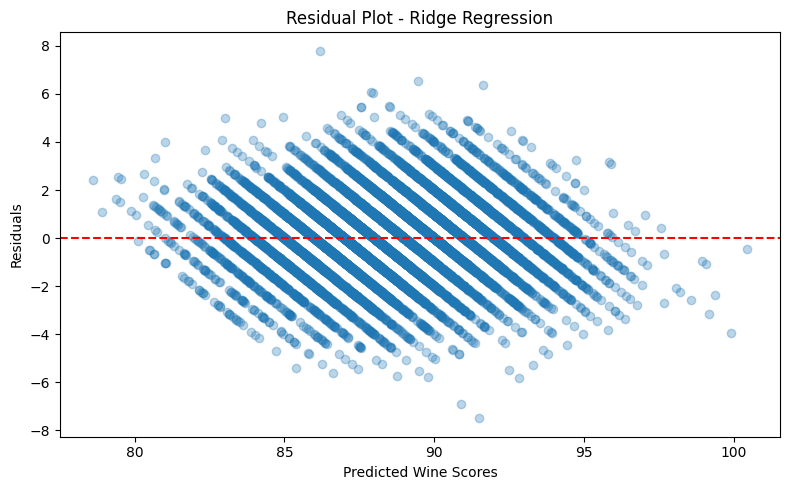

In [32]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_val - ridge_predictions

# Plot residuals
plt.figure(figsize=(8, 5))

plt.scatter(ridge_predictions, residuals, alpha=0.3)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Wine Scores")
plt.ylabel("Residuals")
plt.title("Residual Plot - Ridge Regression")

plt.tight_layout()
plt.savefig("residual_plot.png", dpi=300)
plt.show()

In [33]:
# Create results dataframe
results_df = pd.DataFrame({
    'Actual': y_val,
    'Predicted': ridge_predictions
})

# Define score bands
results_df['Score Band'] = pd.cut(
    results_df['Actual'],
    bins=[79, 84, 89, 94, 100],
    labels=['80-84', '85-89', '90-94', '95-100']
)

# Calculate MAE for each band
band_mae = results_df.groupby(
    'Score Band', observed=False
).apply(
    lambda group: mean_absolute_error(
        group['Actual'], group['Predicted']
    )
)

print("MAE by Score Bands:")
print(band_mae)

MAE by Score Bands:
Score Band
80-84     1.667900
85-89     1.101990
90-94     1.287927
95-100    2.087798
dtype: float64


/tmp/ipykernel_3161/852507272.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(


In [34]:
# Evaluate Combined Ridge Model on Test Set
test_predictions = ridge_model.predict(X_test_combined)

print("Final Test Results - Ridge Regression")
print("MAE:", mean_absolute_error(y_test, test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, test_predictions)))
print("R2 Score:", r2_score(y_test, test_predictions))

Final Test Results - Ridge Regression
MAE: 1.2179778918540882
RMSE: 1.5602593022704099
R2 Score: 0.7454213508227647


In [35]:
baseline_test_predictions = baseline_model.predict(X_test_meta)

print("Baseline Test Results")
print("MAE:", mean_absolute_error(y_test, baseline_test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, baseline_test_predictions)))
print("R2 Score:", r2_score(y_test, baseline_test_predictions))

Baseline Test Results
MAE: 2.529015116297716
RMSE: 3.0923398659271797
R2 Score: -6.574706050477275e-06


In [36]:
metadata_test_predictions = metadata_ridge.predict(X_test_meta)

print("Metadata-only Test Results")
print("MAE:", mean_absolute_error(y_test, metadata_test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, metadata_test_predictions)))
print("R2 Score:", r2_score(y_test, metadata_test_predictions))

Metadata-only Test Results
MAE: 1.9285894873622251
RMSE: 2.4168385638279406
R2 Score: 0.38916529925117294


In [37]:
text_test_predictions = text_ridge.predict(X_test_text_tfidf)

print("Text-only Test Results")
print("MAE:", mean_absolute_error(y_test, text_test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, text_test_predictions)))
print("R2 Score:", r2_score(y_test, text_test_predictions))

Text-only Test Results
MAE: 1.3489584928594927
RMSE: 1.7131071565835323
R2 Score: 0.6930995851841197


In [38]:
final_results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Metadata-only Ridge',
        'Text-only Ridge',
        'Combined Ridge'
    ],
    'MAE': [
        2.5290,
        1.9286,
        1.3490,
        1.2180
    ],
    'RMSE': [
        3.0923,
        2.4168,
        1.7131,
        1.5603
    ],
    'R2 Score': [
        -0.0000066,
        0.3892,
        0.6931,
        0.7454
    ]
})

display(final_results)

,Model,MAE,RMSE,R2 Score
0,Baseline,2.5290,3.0923,-0.000007
1,Metadata-only Ridge,1.9286,2.4168,0.389200
2,Text-only Ridge,1.3490,1.7131,0.693100
3,Combined Ridge,1.2180,1.5603,0.745400


In [39]:
sgd_test_predictions = sgd_model.predict(X_test_combined)

print("SGDRegressor Test Results")
print("MAE:", mean_absolute_error(y_test, sgd_test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, sgd_test_predictions)))
print("R2 Score:", r2_score(y_test, sgd_test_predictions))

SGDRegressor Test Results
MAE: 1.5845706272178621
RMSE: 2.002112311417953
R2 Score: 0.5808154290049479


In [40]:
gb_test_predictions = gb_model.predict(X_test_meta.toarray())

print("Gradient Boosting Test Results")
print("MAE:", mean_absolute_error(y_test, gb_test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, gb_test_predictions)))
print("R2 Score:", r2_score(y_test, gb_test_predictions))

Gradient Boosting Test Results
MAE: 1.9255038245547356
RMSE: 2.4153242488672038
R2 Score: 0.3899305190329112


In [41]:
final_model_results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Metadata-only Ridge',
        'Text-only Ridge',
        'Combined Ridge',
        'SGDRegressor',
        'Gradient Boosting (Metadata-only)'
    ],
    'MAE': [
        2.5290, 1.9286, 1.3490,
        1.2180, 1.5846, 1.9255
    ],
    'RMSE': [
        3.0923, 2.4168, 1.7131,
        1.5603, 2.0021, 2.4153
    ],
    'R2 Score': [
        -0.000007, 0.3892, 0.6931,
        0.7454, 0.5808, 0.3899
    ]
})

display(final_model_results)

,Model,MAE,RMSE,R2 Score
0,Baseline,2.5290,3.0923,-0.000007
1,Metadata-only Ridge,1.9286,2.4168,0.389200
2,Text-only Ridge,1.3490,1.7131,0.693100
3,Combined Ridge,1.2180,1.5603,0.745400
4,SGDRegressor,1.5846,2.0021,0.580800
5,Gradient Boosting (Metadata-only),1.9255,2.4153,0.389900
